In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler,LabelEncoder,OrdinalEncoder,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.datasets import load_breast_cancer

In [ ]:
d = load_breast_cancer()

In [ ]:
df = pd.DataFrame(d.data,columns=d.feature_names)

In [ ]:
df2 = pd.Series(d.target,name='target')

In [ ]:
df = pd.concat([df,df2],axis=1)

In [ ]:
df.describe().round(2)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,...,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,...,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08,0.63
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,...,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02,0.48
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,...,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06,0.00
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,...,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07,0.00
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,...,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08,1.00
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,...,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09,1.00
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,...,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21,1.00


In [ ]:
df.isna().sum().sum()

np.int64(0)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
x = df.drop('target',axis=1)


In [ ]:
nums=x.select_dtypes(include='number').columns

In [ ]:
len(nums)

30

In [ ]:
import math

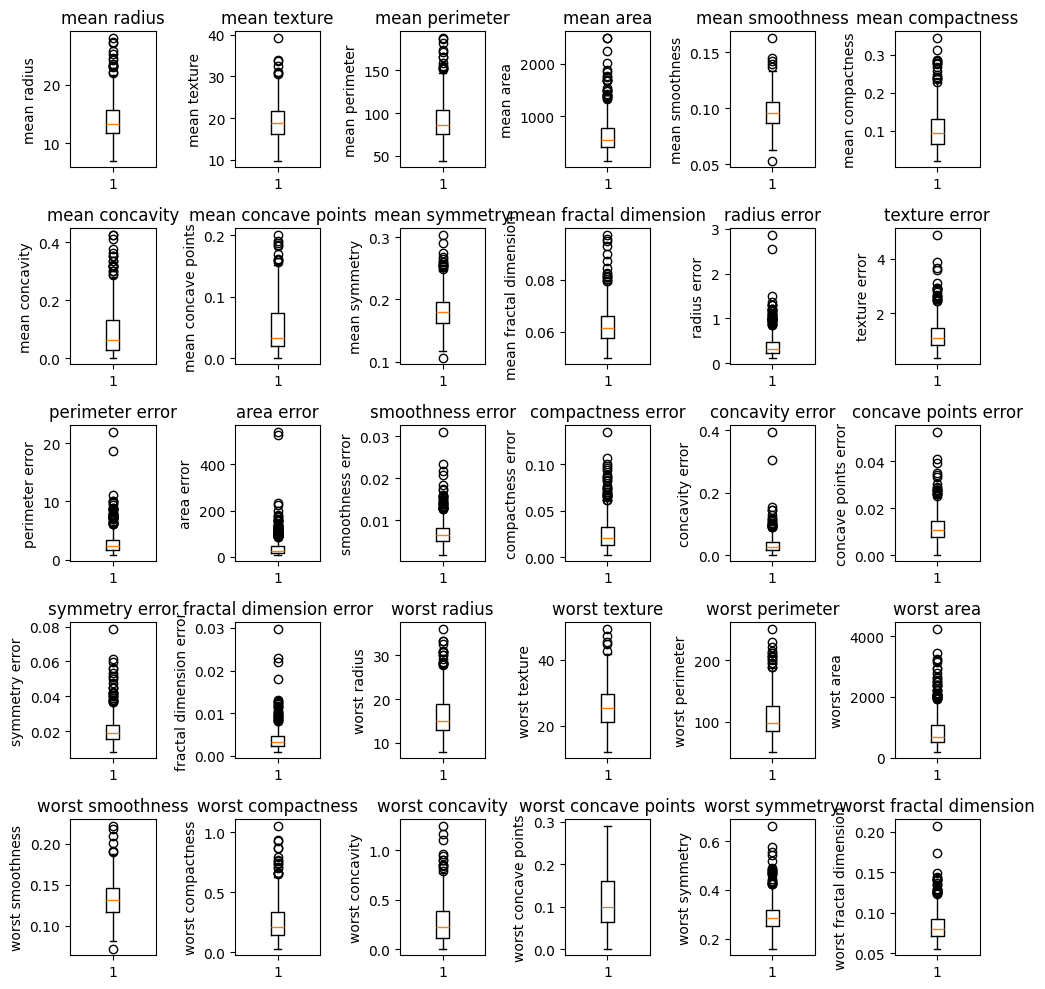

In [ ]:
l = len(nums)
s = math.ceil(l/2)
fig,ax = plt.subplots(5,6,figsize=(10,10))
ax = ax.flatten()
for i, col in enumerate(nums):
  ax[i].boxplot(df[col])
  ax[i].set_title(f'{col}')
  ax[i].set_ylabel(col)
for i in range(l,len(ax)):
  fig.delaxes(ax[i])
plt.tight_layout()
plt.show()

In [ ]:
q1 = df[nums].quantile(0.25)
q3 = df[nums].quantile(0.75)
IQR = q3 - q1
lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR
mask = ((df[nums] < lower_bound) | (df[nums] > upper_bound)).any(axis=1)
df = df[~mask]

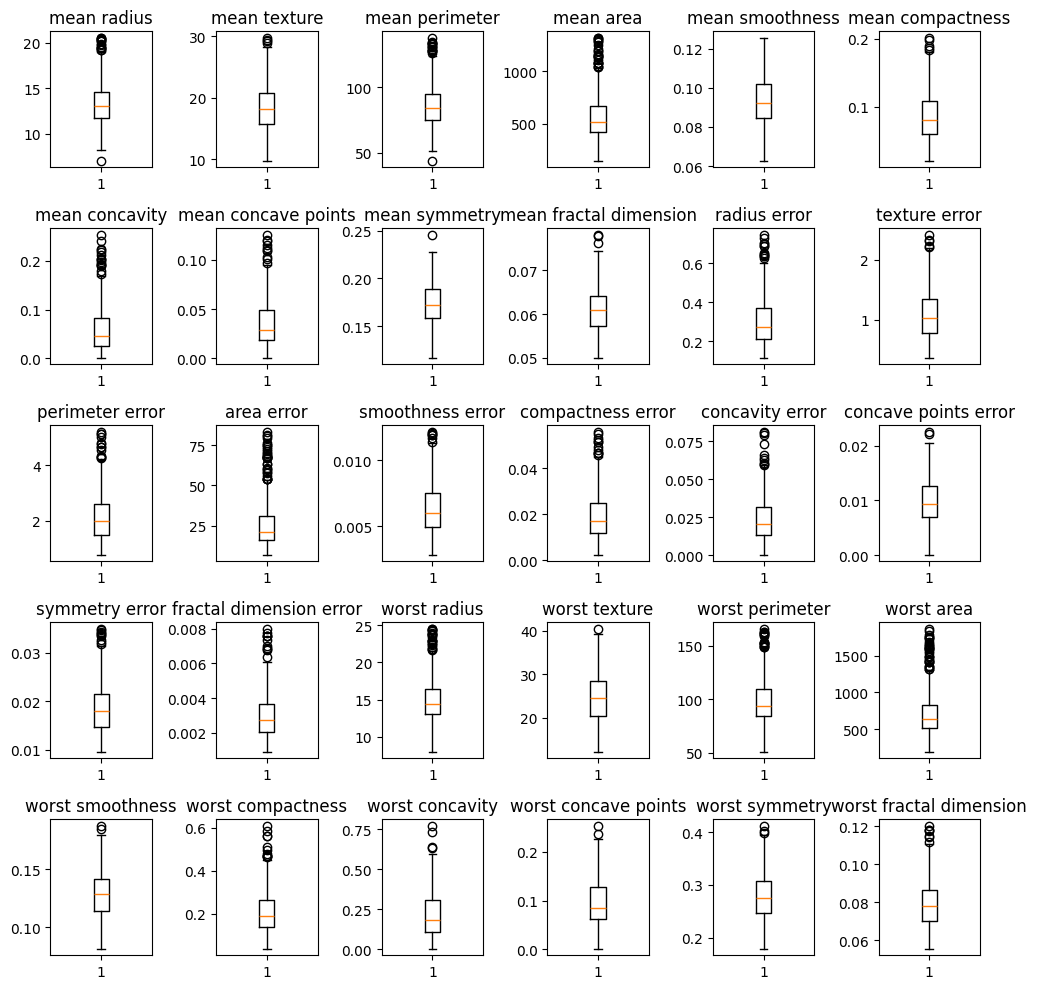

In [ ]:
l2 = len(nums)
c2 = math.ceil(l/2)
fig,ax = plt.subplots(5,6,figsize=(10,10))
ax = ax.flatten()
for i, col in enumerate(nums):
  ax[i].boxplot(df[col])
  ax[i].set_title(f'{col}')
for i in range(l2,len(ax)):
  fig.delaxes(ax[i])
plt.tight_layout()
plt.show()

In [ ]:
df.isna().sum().sum()

np.int64(0)

In [ ]:
df['target'].value_counts()

,count
target,
1,300
0,98


In [ ]:
x = df.drop('target',axis=1)
y= df['target']

In [ ]:
sm = SMOTE()

In [ ]:
x_resampled,y_resampled = sm.fit_resample(x,y)

In [ ]:
y_resampled.value_counts()

,count
target,
0,300
1,300


In [ ]:
from sklearn.feature_selection import SelectKBest,f_classif

In [ ]:
kb = SelectKBest(score_func=f_classif,k=10)
new = kb.fit(x_resampled,y_resampled)

In [ ]:
mask = kb.get_support()
best_df = x_resampled.columns[mask]
best_df

Index(['mean radius', 'mean perimeter', 'mean area', 'mean concavity',
       'mean concave points', 'worst radius', 'worst perimeter', 'worst area',
       'worst concavity', 'worst concave points'],
      dtype='object')

In [ ]:
b = x_resampled.loc[:,best_df]
b.shape

(600, 10)

In [ ]:
y_resampled.shape

(600,)

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(b,y_resampled,test_size=0.2,random_state=42)

In [ ]:
lr = LogisticRegression()
lr.fit(x_train,y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [ ]:
lr.score(x_train,y_train)

0.9416666666666667

In [ ]:
y_predict= lr.predict(x_test)

In [ ]:
accuracy_score(y_test,y_predict)

0.9583333333333334

<Axes: >

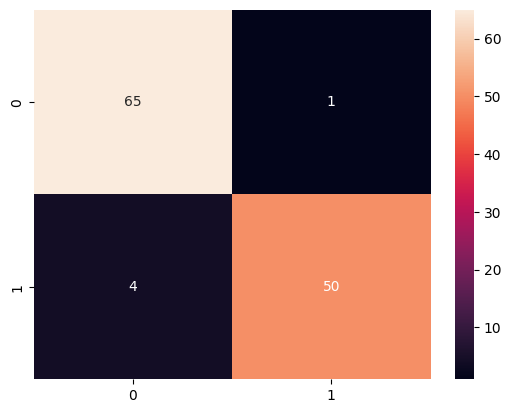

In [ ]:
sns.heatmap(confusion_matrix(y_test,y_predict),annot=True)

In [ ]:
print(classification_report(y_test,y_predict))

              precision    recall  f1-score   support

           0       0.94      0.98      0.96        66
           1       0.98      0.93      0.95        54

    accuracy                           0.96       120
   macro avg       0.96      0.96      0.96       120
weighted avg       0.96      0.96      0.96       120

